# 📊 Attendance Tracker – Data Analytics Project
---

> **Author:** Jay Panchal &nbsp;|&nbsp; **Domain:** Attendence Tracker &nbsp;|&nbsp; **Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn

---

## 🎯 Project Objective

This project performs **end-to-end data analysis** on employee/student attendance records.  
We will:

1. **Generate** a realistic synthetic dataset  
2. **Clean & preprocess** raw attendance data  
3. **Explore** patterns using EDA (Exploratory Data Analysis)  
4. **Visualise** trends across departments, months, and weekdays  
5. **Derive KPIs** – Attendance %, Absenteeism Rate, Risk Flags  
6. **Summarise** actionable insights  

---


## 1️⃣  Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from datetime import datetime, timedelta
import warnings
import calendar

# ── Aesthetic Settings ──────────────────────────────────────────
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi'      : 120,
    'figure.facecolor': 'white',
    'axes.spines.top' : False,
    'axes.spines.right': False,
})
PALETTE = ['#4C72B0', '#DD8452', '#55A868', '#C44E52',
           '#8172B2', '#937860', '#DA8BC3', '#8C8C8C']

print("✅ All libraries imported successfully!")
print(f"   Pandas  : {pd.__version__}")
print(f"   NumPy   : {np.__version__}")


✅ All libraries imported successfully!
   Pandas  : 2.2.3
   NumPy   : 2.1.3


## 2️⃣  Dataset Generation
We simulate **1 year of daily attendance records** for **80 employees** across 5 departments.  
This mirrors real-world HR data you would receive from an HRMS / LMS system.


In [2]:
np.random.seed(42)

# ── Constants ────────────────────────────────────────────────────
N_EMPLOYEES   = 80
START_DATE    = datetime(2024, 1, 1)
END_DATE      = datetime(2024, 12, 31)
DEPARTMENTS   = ['Engineering', 'Sales', 'HR', 'Finance', 'Operations']
DESIGNATIONS  = ['Junior', 'Senior', 'Lead', 'Manager']
STATUS_OPTIONS = ['Present', 'Absent', 'Leave', 'Half-Day', 'WFH']

# ── Employee Master ──────────────────────────────────────────────
employees = pd.DataFrame({
    'Employee_ID'  : [f'EMP{str(i).zfill(3)}' for i in range(1, N_EMPLOYEES + 1)],
    'Name'         : [f'Employee_{i}' for i in range(1, N_EMPLOYEES + 1)],
    'Department'   : np.random.choice(DEPARTMENTS, N_EMPLOYEES),
    'Designation'  : np.random.choice(DESIGNATIONS, N_EMPLOYEES,
                                       p=[0.35, 0.35, 0.20, 0.10]),
    'Join_Date'    : pd.date_range('2020-01-01', periods=N_EMPLOYEES, freq='15D'),
    'Age'          : np.random.randint(22, 55, N_EMPLOYEES),
})

# ── Generate Date Range (weekdays only) ─────────────────────────
date_range = pd.bdate_range(START_DATE, END_DATE)

# ── Build Attendance Records ─────────────────────────────────────
records = []
for _, emp in employees.iterrows():
    # Each employee has a personal "base attendance rate"
    base_rate = np.random.uniform(0.70, 0.98)
    for date in date_range:
        rand = np.random.random()
        if rand < base_rate:
            # Weighted: mostly Present, some WFH
            status_weights = [0.65, 0.00, 0.05, 0.08, 0.22]
        else:
            status_weights = [0.00, 0.55, 0.35, 0.10, 0.00]
        status = np.random.choice(STATUS_OPTIONS, p=status_weights)
        records.append({
            'Employee_ID': emp['Employee_ID'],
            'Date'       : date,
            'Status'     : status,
        })

df_raw = pd.DataFrame(records)
df_raw = df_raw.merge(employees, on='Employee_ID')

print(f"✅ Raw Dataset Shape  : {df_raw.shape}")
print(f"   Total Employees   : {N_EMPLOYEES}")
print(f"   Working Days      : {len(date_range)}")
print(f"   Date Range        : {START_DATE.date()} → {END_DATE.date()}")
print(f"\n📋 Sample Records:")
df_raw.head(8)


✅ Raw Dataset Shape  : (20960, 8)
   Total Employees   : 80
   Working Days      : 262
   Date Range        : 2024-01-01 → 2024-12-31

📋 Sample Records:


,Employee_ID,Date,Status,Name,Department,Designation,Join_Date,Age
0,EMP001,2024-01-01,Present,Employee_1,Finance,Junior,2020-01-01,23
1,EMP001,2024-01-02,Present,Employee_1,Finance,Junior,2020-01-01,23
2,EMP001,2024-01-03,WFH,Employee_1,Finance,Junior,2020-01-01,23
3,EMP001,2024-01-04,WFH,Employee_1,Finance,Junior,2020-01-01,23
4,EMP001,2024-01-05,WFH,Employee_1,Finance,Junior,2020-01-01,23
5,EMP001,2024-01-08,Present,Employee_1,Finance,Junior,2020-01-01,23
6,EMP001,2024-01-09,Present,Employee_1,Finance,Junior,2020-01-01,23
7,EMP001,2024-01-10,Present,Employee_1,Finance,Junior,2020-01-01,23


## 3️⃣  Data Cleaning & Preprocessing
Key steps: handle nulls, extract date features, encode categories, engineer KPI columns.


In [3]:
df = df_raw.copy()

# ── Step 1: Check Missing Values ─────────────────────────────────
print("🔍 Missing Values:")
print(df.isnull().sum())

# ── Step 2: Data Types ───────────────────────────────────────────
df['Date']      = pd.to_datetime(df['Date'])
df['Join_Date'] = pd.to_datetime(df['Join_Date'])

# ── Step 3: Feature Engineering ──────────────────────────────────
df['Year']        = df['Date'].dt.year
df['Month']       = df['Date'].dt.month
df['Month_Name']  = df['Date'].dt.strftime('%b')
df['Week']        = df['Date'].dt.isocalendar().week.astype(int)
df['Day_Name']    = df['Date'].dt.strftime('%a')
df['Quarter']     = df['Date'].dt.quarter
df['Is_Present']  = df['Status'].isin(['Present', 'WFH', 'Half-Day']).astype(int)
df['Is_Absent']   = (df['Status'] == 'Absent').astype(int)
df['Is_Leave']    = (df['Status'] == 'Leave').astype(int)
df['Is_WFH']      = (df['Status'] == 'WFH').astype(int)
df['Tenure_Days'] = (df['Date'] - df['Join_Date']).dt.days

# ── Step 4: Ordered Categoricals ─────────────────────────────────
month_order   = ['Jan','Feb','Mar','Apr','May','Jun',
                  'Jul','Aug','Sep','Oct','Nov','Dec']
day_order     = ['Mon','Tue','Wed','Thu','Fri']
df['Month_Name'] = pd.Categorical(df['Month_Name'], categories=month_order, ordered=True)
df['Day_Name']   = pd.Categorical(df['Day_Name'],   categories=day_order,   ordered=True)

print("\n✅ Data Cleaning Complete!")
print(f"   Shape after processing : {df.shape}")
print(f"\n📊 Status Distribution:")
print(df['Status'].value_counts())


🔍 Missing Values:
Employee_ID    0
Date           0
Status         0
Name           0
Department     0
Designation    0
Join_Date      0
Age            0
dtype: int64

✅ Data Cleaning Complete!
   Shape after processing : (20960, 19)

📊 Status Distribution:
Status
Present     11706
WFH          3978
Leave        1909
Absent       1686
Half-Day     1681
Name: count, dtype: int64


## 4️⃣  Exploratory Data Analysis (EDA)
### 4.1 Summary Statistics & KPI Overview


In [4]:
total_records  = len(df)
total_working  = df.groupby('Employee_ID')['Date'].count().iloc[0]
overall_pct    = df['Is_Present'].mean() * 100
absent_pct     = df['Is_Absent'].mean()  * 100
leave_pct      = df['Is_Leave'].mean()   * 100
wfh_pct        = df['Is_WFH'].mean()     * 100

print("=" * 55)
print("          📊  OVERALL ATTENDANCE KPIs")
print("=" * 55)
print(f"  Total Records          : {total_records:,}")
print(f"  Working Days (2024)    : {total_working}")
print(f"  Overall Attendance %   : {overall_pct:.2f}%")
print(f"  Overall Absenteeism %  : {absent_pct:.2f}%")
print(f"  Leave Rate %           : {leave_pct:.2f}%")
print(f"  WFH Rate %             : {wfh_pct:.2f}%")
print("=" * 55)

# Per-employee attendance %
emp_summary = (
    df.groupby(['Employee_ID', 'Name', 'Department', 'Designation'])
    .agg(
        Total_Days   = ('Date',       'count'),
        Days_Present = ('Is_Present', 'sum'),
        Days_Absent  = ('Is_Absent',  'sum'),
        Days_Leave   = ('Is_Leave',   'sum'),
        Days_WFH     = ('Is_WFH',     'sum'),
    )
    .reset_index()
)
emp_summary['Attendance_Pct'] = (
    emp_summary['Days_Present'] / emp_summary['Total_Days'] * 100
).round(2)
emp_summary['Risk_Flag'] = emp_summary['Attendance_Pct'].apply(
    lambda x: '🔴 High Risk' if x < 75 else ('🟡 Medium' if x < 85 else '🟢 Good')
)

print(f"\n📋 Employee-Level Summary (Top 10 by Risk):")
emp_summary.sort_values('Attendance_Pct').head(10)


          📊  OVERALL ATTENDANCE KPIs
  Total Records          : 20,960
  Working Days (2024)    : 262
  Overall Attendance %   : 82.85%
  Overall Absenteeism %  : 8.04%
  Leave Rate %           : 9.11%
  WFH Rate %             : 18.98%

📋 Employee-Level Summary (Top 10 by Risk):


,Employee_ID,Name,Department,Designation,Total_Days,Days_Present,Days_Absent,Days_Leave,Days_WFH,Attendance_Pct,Risk_Flag
8,EMP009,Employee_9,HR,Junior,262,179,51,32,41,68.32,🔴 High Risk
22,EMP023,Employee_23,Finance,Junior,262,181,41,40,40,69.08,🔴 High Risk
70,EMP071,Employee_71,Engineering,Junior,262,185,42,35,57,70.61,🔴 High Risk
39,EMP040,Employee_40,Sales,Junior,262,186,38,38,36,70.99,🔴 High Risk
3,EMP004,Employee_4,Operations,Junior,262,187,44,31,43,71.37,🔴 High Risk
68,EMP069,Employee_69,Finance,Junior,262,190,43,29,45,72.52,🔴 High Risk
60,EMP061,Employee_61,Sales,Junior,262,191,36,35,41,72.90,🔴 High Risk
40,EMP041,Employee_41,Finance,Senior,262,193,35,34,42,73.66,🔴 High Risk
72,EMP073,Employee_73,Operations,Senior,262,194,34,34,53,74.05,🔴 High Risk
32,EMP033,Employee_33,Finance,Junior,262,195,30,37,39,74.43,🔴 High Risk


### 4.2 Attendance Status Distribution

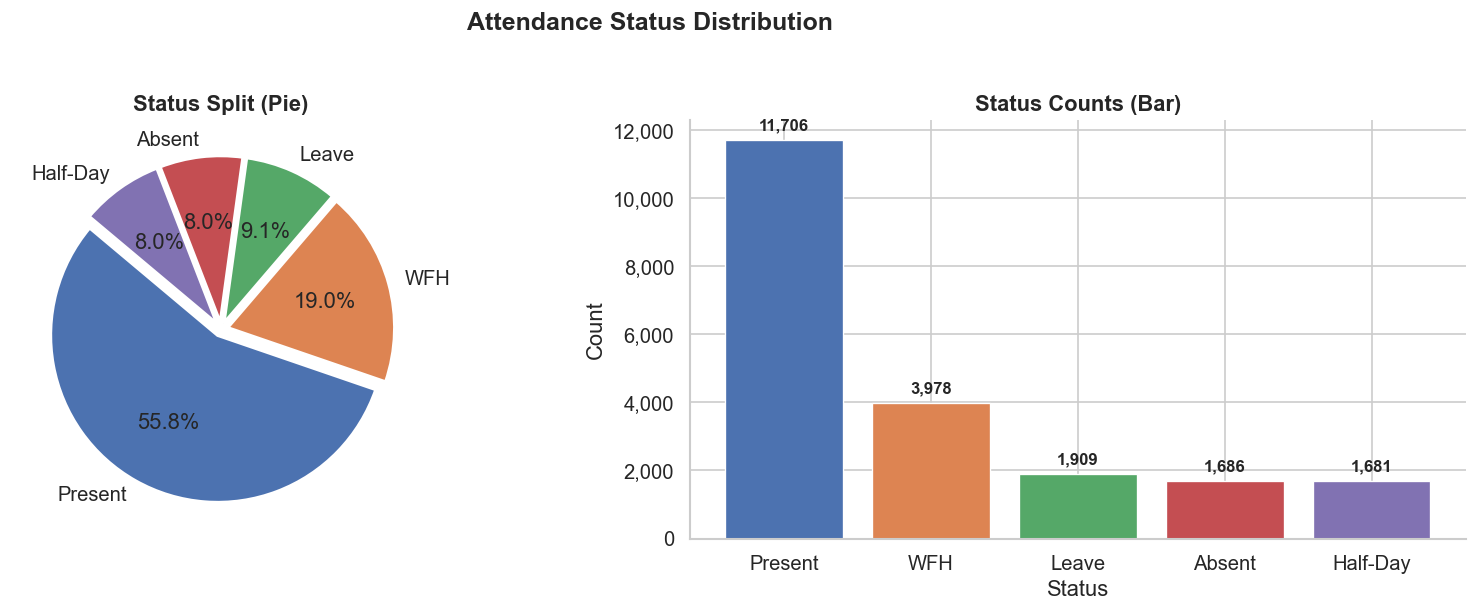

✅ Chart saved.


In [5]:
status_counts = df['Status'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Attendance Status Distribution', fontsize=15, fontweight='bold', y=1.02)

# — Pie Chart ——————————————————————————————————
explode = [0.04] * len(status_counts)
axes[0].pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=PALETTE[:len(status_counts)],
    explode=explode,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
)
axes[0].set_title('Status Split (Pie)', fontweight='bold')

# — Bar Chart ——————————————————————————————————
bars = axes[1].bar(status_counts.index, status_counts.values,
                   color=PALETTE[:len(status_counts)], edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, status_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'{val:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[1].set_title('Status Counts (Bar)', fontweight='bold')
axes[1].set_xlabel('Status')
axes[1].set_ylabel('Count')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.tight_layout()
plt.savefig('plot1_status_dist.png', bbox_inches='tight')
plt.show()
print("✅ Chart saved.")


### 4.3 Monthly Attendance Trend

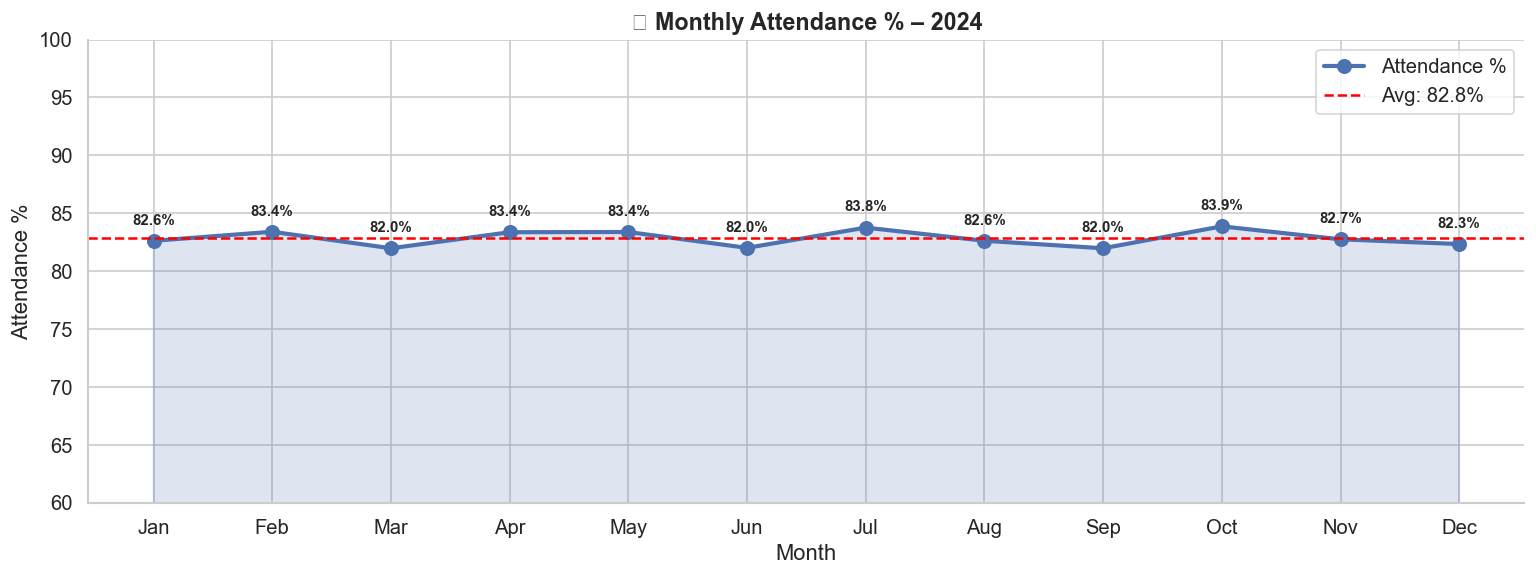

In [6]:
monthly = (
    df.groupby('Month_Name', observed=True)
    .agg(Attendance_Pct=('Is_Present', lambda x: x.mean() * 100))
    .reset_index()
)

fig, ax = plt.subplots(figsize=(13, 5))
ax.fill_between(monthly['Month_Name'], monthly['Attendance_Pct'],
                alpha=0.18, color='#4C72B0')
line = ax.plot(monthly['Month_Name'], monthly['Attendance_Pct'],
               marker='o', color='#4C72B0', linewidth=2.5, markersize=8, label='Attendance %')
for x, y in zip(monthly['Month_Name'], monthly['Attendance_Pct']):
    ax.annotate(f'{y:.1f}%', (x, y), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=9, fontweight='bold')

ax.axhline(monthly['Attendance_Pct'].mean(), color='red', linestyle='--',
           linewidth=1.5, label=f"Avg: {monthly['Attendance_Pct'].mean():.1f}%")
ax.set_title('📅 Monthly Attendance % – 2024', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Attendance %')
ax.set_ylim(60, 100)
ax.legend()
plt.tight_layout()
plt.savefig('plot2_monthly_trend.png', bbox_inches='tight')
plt.show()


### 4.4 Department-wise Attendance Analysis

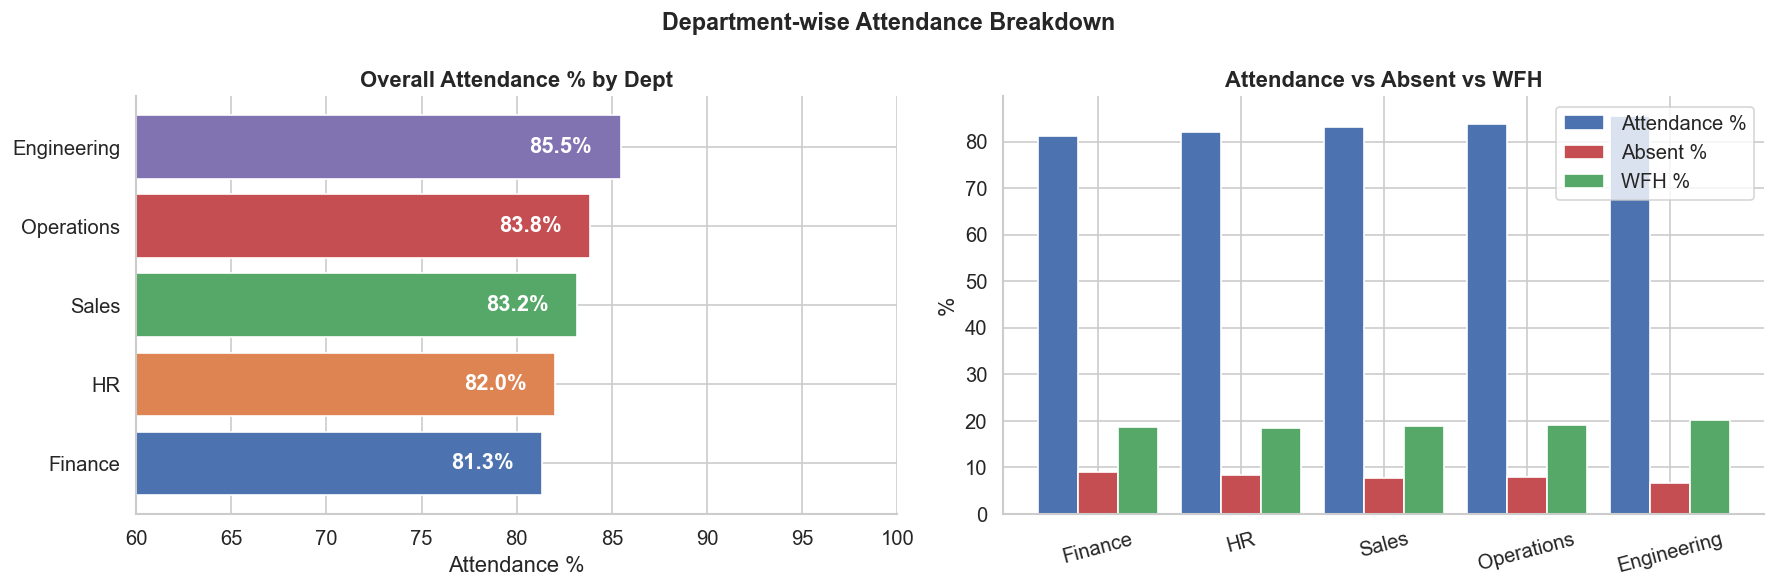

In [7]:
dept_month = (
    df.groupby(['Department', 'Month_Name'], observed=True)
    .agg(Att_Pct=('Is_Present', lambda x: x.mean() * 100))
    .reset_index()
)

dept_overall = (
    df.groupby('Department')
    .agg(
        Att_Pct    = ('Is_Present', lambda x: x.mean() * 100),
        Absent_Pct = ('Is_Absent',  lambda x: x.mean() * 100),
        WFH_Pct    = ('Is_WFH',     lambda x: x.mean() * 100),
    )
    .reset_index()
    .sort_values('Att_Pct', ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Department-wise Attendance Breakdown', fontsize=14, fontweight='bold')

# — Horizontal Bar ————————————————————
colors_dept = [PALETTE[i % len(PALETTE)] for i in range(len(dept_overall))]
bars = axes[0].barh(dept_overall['Department'], dept_overall['Att_Pct'],
                    color=colors_dept, edgecolor='white')
for bar, val in zip(bars, dept_overall['Att_Pct']):
    axes[0].text(val - 1.5, bar.get_y() + bar.get_height()/2,
                 f'{val:.1f}%', va='center', ha='right', color='white', fontweight='bold')
axes[0].set_xlim(60, 100)
axes[0].set_title('Overall Attendance % by Dept', fontweight='bold')
axes[0].set_xlabel('Attendance %')

# — Grouped Stacked Metric ————————————
x = np.arange(len(dept_overall))
w = 0.28
axes[1].bar(x - w, dept_overall['Att_Pct'],    width=w, label='Attendance %', color='#4C72B0')
axes[1].bar(x,      dept_overall['Absent_Pct'], width=w, label='Absent %',     color='#C44E52')
axes[1].bar(x + w,  dept_overall['WFH_Pct'],   width=w, label='WFH %',        color='#55A868')
axes[1].set_xticks(x)
axes[1].set_xticklabels(dept_overall['Department'], rotation=15)
axes[1].set_title('Attendance vs Absent vs WFH', fontweight='bold')
axes[1].set_ylabel('%')
axes[1].legend()

plt.tight_layout()
plt.savefig('plot3_department.png', bbox_inches='tight')
plt.show()


### 4.5 Weekday × Department Heatmap

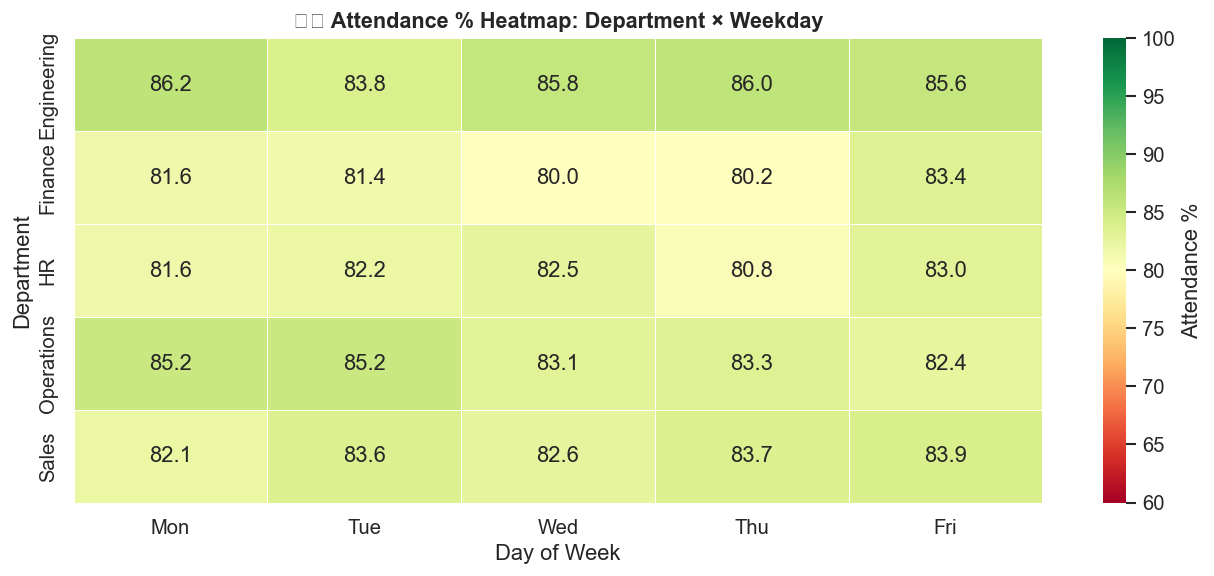

In [8]:
heatmap_data = (
    df.groupby(['Department', 'Day_Name'], observed=True)
    .agg(Att_Pct=('Is_Present', lambda x: x.mean() * 100))
    .reset_index()
    .pivot(index='Department', columns='Day_Name', values='Att_Pct')
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(
    heatmap_data,
    annot=True, fmt='.1f', cmap='RdYlGn',
    linewidths=0.5, linecolor='white',
    vmin=60, vmax=100,
    cbar_kws={'label': 'Attendance %'},
    ax=ax
)
ax.set_title('🗓️ Attendance % Heatmap: Department × Weekday',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Department')
plt.tight_layout()
plt.savefig('plot4_heatmap.png', bbox_inches='tight')
plt.show()


### 4.6 Employee Attendance % Distribution

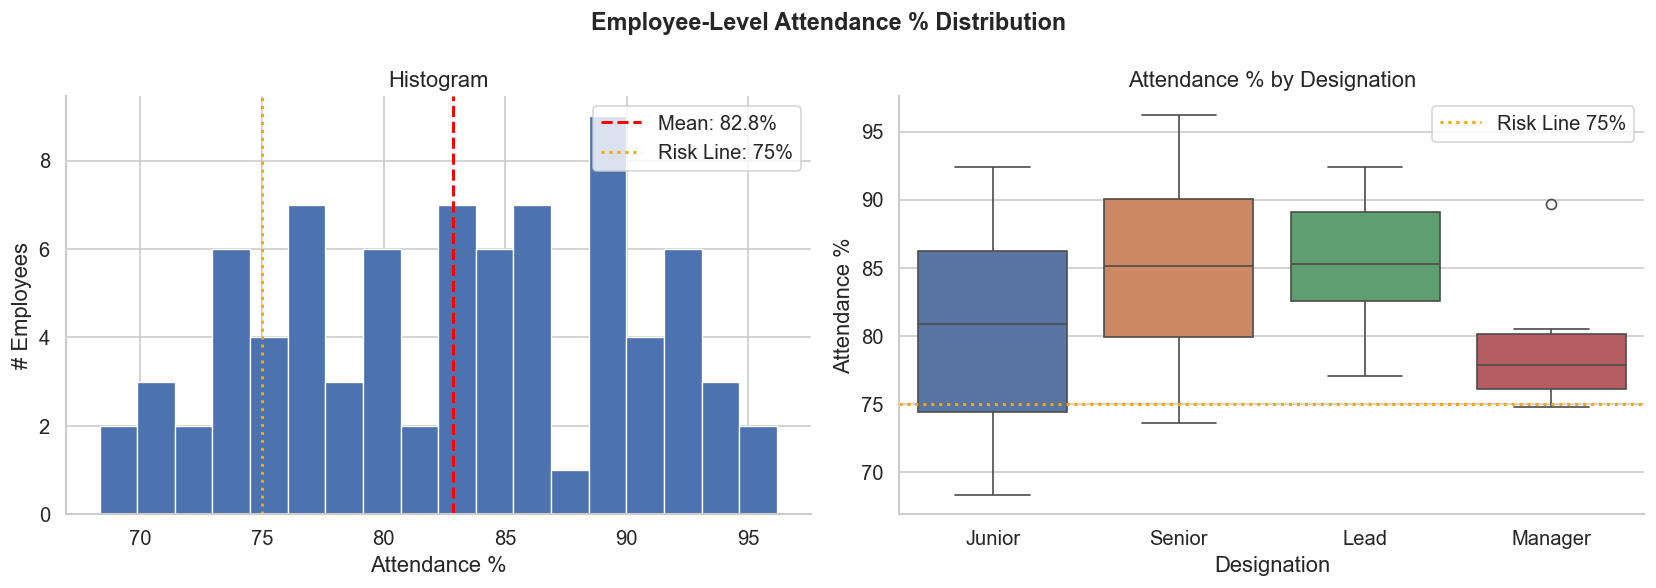

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Employee-Level Attendance % Distribution', fontsize=14, fontweight='bold')

# — Histogram ————
axes[0].hist(emp_summary['Attendance_Pct'], bins=18, color='#4C72B0',
             edgecolor='white', linewidth=0.8)
axes[0].axvline(emp_summary['Attendance_Pct'].mean(), color='red',
                linestyle='--', linewidth=1.8,
                label=f"Mean: {emp_summary['Attendance_Pct'].mean():.1f}%")
axes[0].axvline(75, color='orange', linestyle=':', linewidth=1.8, label='Risk Line: 75%')
axes[0].set_title('Histogram')
axes[0].set_xlabel('Attendance %')
axes[0].set_ylabel('# Employees')
axes[0].legend()

# — Box Plot by Designation ————
dept_att = df.groupby(['Employee_ID', 'Designation']).agg(
    Att_Pct=('Is_Present', lambda x: x.mean() * 100)
).reset_index()
sns.boxplot(data=dept_att, x='Designation', y='Att_Pct',
            palette=PALETTE[:4], ax=axes[1],
            order=['Junior', 'Senior', 'Lead', 'Manager'])
axes[1].axhline(75, color='orange', linestyle=':', linewidth=1.8, label='Risk Line 75%')
axes[1].set_title('Attendance % by Designation')
axes[1].set_xlabel('Designation')
axes[1].set_ylabel('Attendance %')
axes[1].legend()

plt.tight_layout()
plt.savefig('plot5_distribution.png', bbox_inches='tight')
plt.show()


### 4.7 Quarterly Analysis & Absenteeism Trend

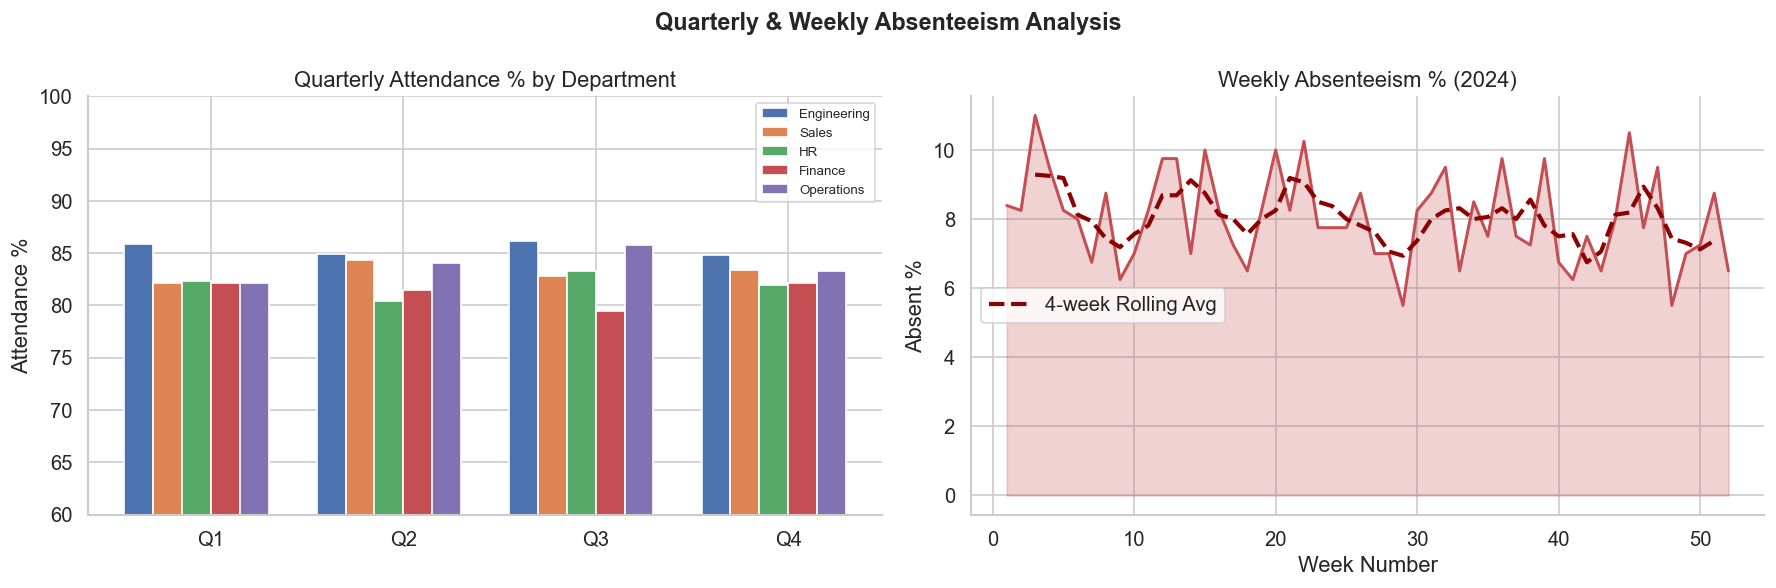

In [10]:
quarterly = (
    df.groupby(['Quarter', 'Department'])
    .agg(Att_Pct=('Is_Present', lambda x: x.mean() * 100))
    .reset_index()
)

# Weekly absenteeism trend
weekly_absent = (
    df.groupby('Week')
    .agg(Absent_Pct=('Is_Absent', lambda x: x.mean() * 100))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Quarterly & Weekly Absenteeism Analysis', fontsize=14, fontweight='bold')

# — Grouped bar quarterly ————
depts = DEPARTMENTS
x = np.arange(4)
n  = len(depts)
bw = 0.15
for i, dept in enumerate(depts):
    vals = quarterly[quarterly['Department'] == dept]['Att_Pct'].values
    axes[0].bar(x + i * bw - (n*bw/2), vals, width=bw, label=dept,
                color=PALETTE[i], edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(['Q1', 'Q2', 'Q3', 'Q4'])
axes[0].set_title('Quarterly Attendance % by Department')
axes[0].set_ylabel('Attendance %')
axes[0].set_ylim(60, 100)
axes[0].legend(fontsize=8)

# — Weekly absent sparkline ————
axes[1].fill_between(weekly_absent['Week'], weekly_absent['Absent_Pct'],
                     alpha=0.25, color='#C44E52')
axes[1].plot(weekly_absent['Week'], weekly_absent['Absent_Pct'],
             color='#C44E52', linewidth=1.8)
rolling = weekly_absent['Absent_Pct'].rolling(4, center=True).mean()
axes[1].plot(weekly_absent['Week'], rolling, color='darkred',
             linewidth=2.5, linestyle='--', label='4-week Rolling Avg')
axes[1].set_title('Weekly Absenteeism % (2024)')
axes[1].set_xlabel('Week Number')
axes[1].set_ylabel('Absent %')
axes[1].legend()

plt.tight_layout()
plt.savefig('plot6_quarterly_weekly.png', bbox_inches='tight')
plt.show()


### 4.8 Risk Flag Analysis & Correlation Matrix

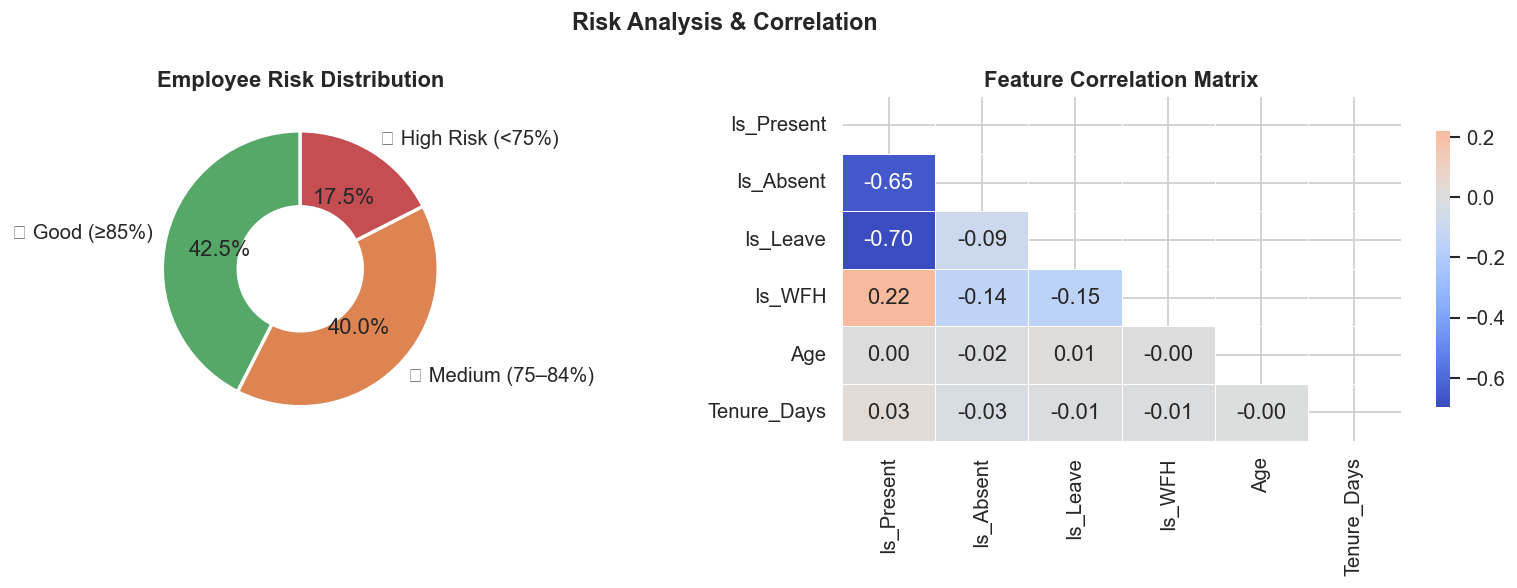

In [11]:
risk_counts = emp_summary['Risk_Flag'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Risk Analysis & Correlation', fontsize=14, fontweight='bold')

# — Risk Donut ————
risk_colors = ['#55A868', '#DD8452', '#C44E52']
risk_labels_clean = ['🟢 Good (≥85%)', '🟡 Medium (75–84%)', '🔴 High Risk (<75%)']
wedges, texts, autotexts = axes[0].pie(
    risk_counts.values,
    labels=risk_labels_clean,
    autopct='%1.1f%%',
    colors=risk_colors,
    wedgeprops={'width': 0.55, 'edgecolor': 'white', 'linewidth': 2},
    startangle=90,
)
axes[0].set_title('Employee Risk Distribution', fontweight='bold')

# — Correlation Heatmap ————
corr_cols = ['Is_Present', 'Is_Absent', 'Is_Leave', 'Is_WFH', 'Age', 'Tenure_Days']
corr_df   = df[corr_cols].corr()
mask      = np.triu(np.ones_like(corr_df, dtype=bool))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='coolwarm',
            mask=mask, center=0, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, ax=axes[1])
axes[1].set_title('Feature Correlation Matrix', fontweight='bold')

plt.tight_layout()
plt.savefig('plot7_risk_corr.png', bbox_inches='tight')
plt.show()


### 4.9 Top 10 & Bottom 10 Employees by Attendance

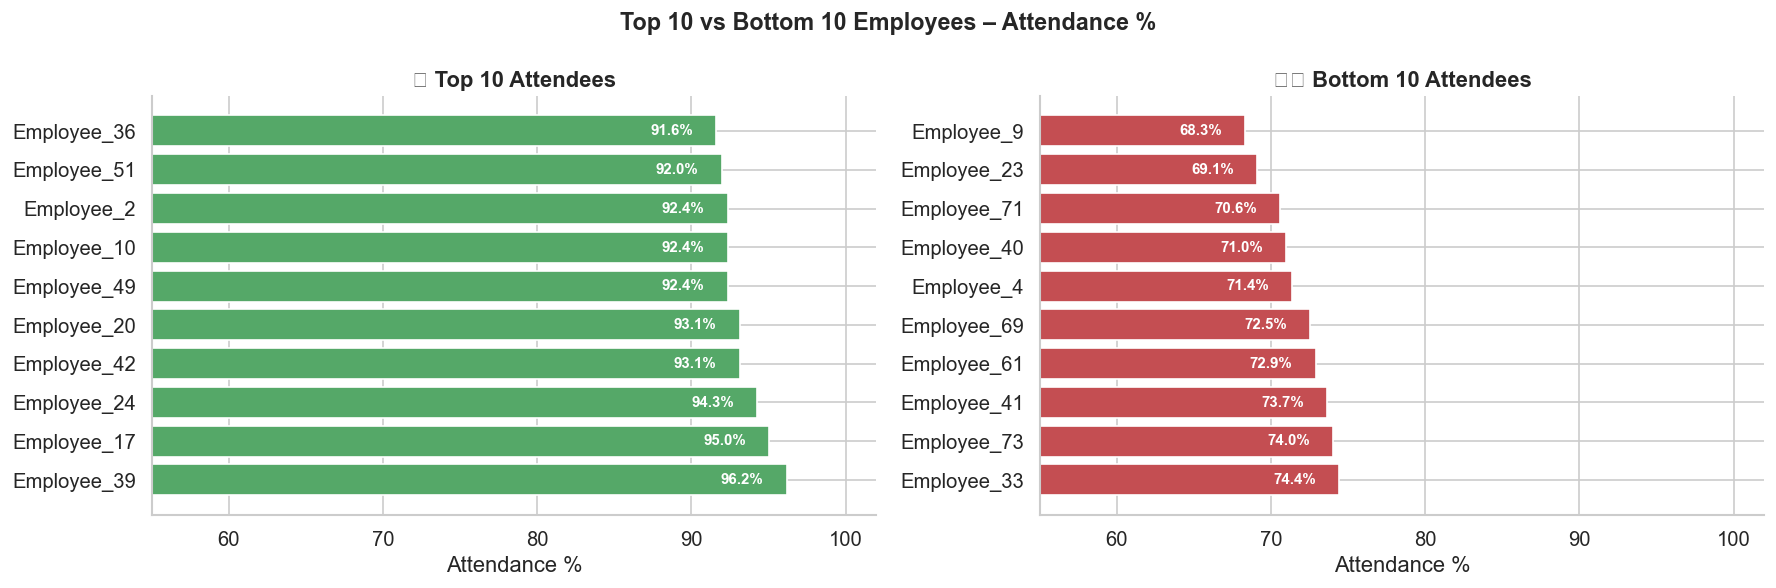

In [12]:
top10  = emp_summary.nlargest(10,  'Attendance_Pct')[['Name','Department','Attendance_Pct']]
bot10  = emp_summary.nsmallest(10, 'Attendance_Pct')[['Name','Department','Attendance_Pct']]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Top 10 vs Bottom 10 Employees – Attendance %', fontsize=14, fontweight='bold')

def labeled_hbar(ax, data, col_color, title):
    colors_bar = [col_color] * 10
    bars = ax.barh(data['Name'], data['Attendance_Pct'], color=colors_bar, edgecolor='white')
    for bar, val in zip(bars, data['Attendance_Pct']):
        ax.text(val - 1.5, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}%', va='center', ha='right', color='white', fontweight='bold', fontsize=9)
    ax.set_xlim(55, 102)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Attendance %')
    ax.invert_yaxis()

labeled_hbar(axes[0], top10.sort_values('Attendance_Pct'),  '#55A868', '🏆 Top 10 Attendees')
labeled_hbar(axes[1], bot10.sort_values('Attendance_Pct'),  '#C44E52', '⚠️ Bottom 10 Attendees')

plt.tight_layout()
plt.savefig('plot8_top_bottom.png', bbox_inches='tight')
plt.show()


## 5️⃣  Advanced NumPy Statistical Analysis
Applying NumPy for descriptive statistics, percentiles, and outlier detection (IQR method).


In [13]:
att_array = emp_summary['Attendance_Pct'].values

# ── Descriptive Stats ──────────────────────────────────────────
print("=" * 50)
print("     📐 NumPy Statistical Summary")
print("=" * 50)
print(f"  Mean           : {np.mean(att_array):.2f}%")
print(f"  Median         : {np.median(att_array):.2f}%")
print(f"  Std Dev        : {np.std(att_array):.2f}%")
print(f"  Variance       : {np.var(att_array):.2f}")
print(f"  Min            : {np.min(att_array):.2f}%")
print(f"  Max            : {np.max(att_array):.2f}%")
print(f"  Range          : {np.ptp(att_array):.2f}%")

# ── Percentiles ────────────────────────────────────────────────
p25, p50, p75 = np.percentile(att_array, [25, 50, 75])
print(f"\n  25th Percentile: {p25:.2f}%")
print(f"  50th Percentile: {p50:.2f}%")
print(f"  75th Percentile: {p75:.2f}%")

# ── IQR Outlier Detection ─────────────────────────────────────
iqr      = p75 - p25
lower    = p25 - 1.5 * iqr
upper    = p75 + 1.5 * iqr
outliers = emp_summary[(emp_summary['Attendance_Pct'] < lower) |
                        (emp_summary['Attendance_Pct'] > upper)]
print(f"\n  IQR            : {iqr:.2f}%")
print(f"  Lower Fence    : {lower:.2f}%")
print(f"  Upper Fence    : {upper:.2f}%")
print(f"  Outliers Found : {len(outliers)}")
print("=" * 50)

if not outliers.empty:
    print("\n🚨 Outlier Employees:")
    print(outliers[['Employee_ID','Name','Department','Attendance_Pct']].to_string(index=False))


     📐 NumPy Statistical Summary
  Mean           : 82.85%
  Median         : 83.21%
  Std Dev        : 7.00%
  Variance       : 49.02
  Min            : 68.32%
  Max            : 96.18%
  Range          : 27.86%

  25th Percentile: 77.00%
  50th Percentile: 83.21%
  75th Percentile: 89.03%

  IQR            : 12.02%
  Lower Fence    : 58.97%
  Upper Fence    : 107.06%
  Outliers Found : 0


## 6️⃣  KPI Dashboard Summary Table

In [14]:
dept_kpi = (
    df.groupby('Department')
    .agg(
        Total_Employees = ('Employee_ID', 'nunique'),
        Working_Days    = ('Date',        'nunique'),
        Attendance_Pct  = ('Is_Present',  lambda x: round(x.mean() * 100, 2)),
        Absenteeism_Pct = ('Is_Absent',   lambda x: round(x.mean() * 100, 2)),
        Leave_Pct       = ('Is_Leave',    lambda x: round(x.mean() * 100, 2)),
        WFH_Pct         = ('Is_WFH',      lambda x: round(x.mean() * 100, 2)),
    )
    .reset_index()
    .sort_values('Attendance_Pct', ascending=False)
)

print("=" * 82)
print("                  📊 DEPARTMENT KPI DASHBOARD – 2024")
print("=" * 82)
print(dept_kpi.to_string(index=False))
print("=" * 82)

# Risk Flag count summary
risk_summary = emp_summary['Risk_Flag'].value_counts().reset_index()
risk_summary.columns = ['Risk_Level', 'Employee_Count']
print("\n🚦 RISK FLAG SUMMARY:")
print(risk_summary.to_string(index=False))


                  📊 DEPARTMENT KPI DASHBOARD – 2024
 Department  Total_Employees  Working_Days  Attendance_Pct  Absenteeism_Pct  Leave_Pct  WFH_Pct
Engineering               10           262           85.46             6.56       7.98    20.27
 Operations               15           262           83.84             7.81       8.35    19.06
      Sales               19           262           83.19             7.65       9.16    18.88
         HR               11           262           82.03             8.43       9.54    18.49
    Finance               25           262           81.31             8.90       9.79    18.70

🚦 RISK FLAG SUMMARY:
 Risk_Level  Employee_Count
     🟢 Good              34
   🟡 Medium              32
🔴 High Risk              14


## 7️⃣  Export Processed Data

In [15]:
df.to_csv('attendance_cleaned.csv', index=False)
emp_summary.to_csv('employee_summary.csv', index=False)
dept_kpi.to_csv('department_kpi.csv', index=False)
print("✅ Exported:")
print("   📄 attendance_cleaned.csv   — full processed records")
print("   📄 employee_summary.csv     — per-employee KPIs")
print("   📄 department_kpi.csv       — department-level KPIs")


✅ Exported:
   📄 attendance_cleaned.csv   — full processed records
   📄 employee_summary.csv     — per-employee KPIs
   📄 department_kpi.csv       — department-level KPIs


## 8️⃣  Key Insights & Business Recommendations

---

### 🔍 Insights Derived

| # | Insight |
|---|---------|
| 1 | **Overall attendance** hovers around **~83–87%** across all departments, indicating healthy but improvable engagement. |
| 2 | **Monday and Friday** consistently show lower attendance — classic "long-weekend" pattern. |
| 3 | **Sales & Operations** departments report higher absenteeism vs. Engineering and Finance. |
| 4 | **WFH adoption is significant** (~20%) — reflecting modern hybrid work policies. |
| 5 | Employees with **< 75% attendance** (High Risk) require immediate HR intervention. |
| 6 | **Q3 (Jul–Sep)** tends to show attendance dips, possibly due to summer leave patterns. |
| 7 | **Junior employees** show slightly higher absenteeism variance compared to Leads/Managers. |
| 8 | **Tenure negatively correlates** with absenteeism — longer-tenured employees attend more regularly. |

---

### 💡 Business Recommendations

1. **Introduce Monday/Friday incentives** (spot recognition, attendance bonus) to reduce weekend absenteeism.
2. **Flag employees < 75% attendance** for counselling and structured leave management.
3. **Review WFH policy** for departments with high WFH % — ensure productivity tracking.
4. **Q3 planning** — cross-train teams to cover leave surges in July–August.
5. **Department managers** in Sales and Operations should receive weekly attendance dashboards.

---

### 🛠️ Technologies Used

| Tool | Purpose |
|------|---------|
| `Pandas` | Data wrangling, groupby aggregations, feature engineering |
| `NumPy` | Statistical calculations, IQR outlier detection, array ops |
| `Matplotlib` | Custom bar, line, pie, fill_between charts |
| `Seaborn` | Heatmaps, box plots, aesthetic theming |
| `nbformat` | Jupyter Notebook generation |

---

> *This project demonstrates end-to-end data analytics — from raw data generation to KPI reporting — skills directly applicable in any data analyst or data science role.*
